In [5]:
import time
import random
import oqs
from cryptography.hazmat.primitives.asymmetric import x25519
from cryptography.hazmat.primitives.kdf.hkdf import HKDF
from cryptography.hazmat.primitives import hashes
from cryptography.hazmat.primitives import serialization

def simulate_network_transmission(payload_bytes, base_latency_ms=15, packet_loss_rate=0.0):
    """
    Simulates sending data over a network with configurable latency and packet loss.
    Returns transmission time in milliseconds and success status.
    """
    if random.random() < packet_loss_rate:
        # Packet lost! Retransmission penalty
        return base_latency_ms * 3, False
    
    # Standard MTU is ~1500 bytes. Check for fragmentation.
    mtu = 1500
    fragments = (len(payload_bytes) + mtu - 1) // mtu
    
    jitter = random.uniform(-2.0, 2.0)
    transmission_time = (base_latency_ms * fragments) + jitter
    
    return max(1.0, transmission_time), True

def run_hybrid_handshake_simulation(network_profile="Standard 4G"):
    if network_profile == "Local Wi-Fi":
        latency, loss = 5.0, 0.00
    elif network_profile == "Standard 4G":
        latency, loss = 45.0, 0.02
    elif network_profile == "High-Latency / Lossy":
        latency, loss = 120.0, 0.08
    else:
        latency, loss = 15.0, 0.00

    start_time = time.perf_counter()

    # 1. Key Generation Phase
    alice_private_x = x25519.X25519PrivateKey.generate()
    alice_public_x = alice_private_x.public_key()
    
    alg_name = "ML-KEM-768"
    with oqs.KeyEncapsulation(alg_name) as bob_kem:
        bob_pq_public_key = bob_kem.generate_keypair()
        
        # Message 1: Client -> Server (Client sends X25519 public key - 32 raw bytes)
        msg1_bytes = alice_public_x.public_bytes(
            encoding=serialization.Encoding.Raw,
            format=serialization.PublicFormat.Raw
        )
        
        t1, success1 = simulate_network_transmission(msg1_bytes, base_latency_ms=latency, packet_loss_rate=loss)
        if not success1:
            return {"status": "Failed (Packet Loss on Msg 1)", "total_time_ms": None}

        # Server responds
        bob_private_x = x25519.X25519PrivateKey.generate()
        bob_public_x = bob_private_x.public_key()
        
        bob_pub_bytes = bob_public_x.public_bytes(
            encoding=serialization.Encoding.Raw,
            format=serialization.PublicFormat.Raw
        )
        
        ciphertext, alice_pq_secret = bob_kem.encap_secret(bob_pq_public_key)
        
        # Message 2: Server -> Client (Server X25519 pub [32 bytes] + ML-KEM Ciphertext [1088 bytes])
        msg2_bytes = bob_pub_bytes + ciphertext
        t2, success2 = simulate_network_transmission(msg2_bytes, base_latency_ms=latency, packet_loss_rate=loss)
        if not success2:
            return {"status": "Failed (Packet Loss on Msg 2)", "total_time_ms": None}

        # Cryptographic Derivation
        alice_classical_secret = alice_private_x.exchange(bob_public_x)
        bob_pq_secret = bob_kem.decap_secret(ciphertext)
        
        combined_secret = alice_classical_secret + alice_pq_secret
        derived_session_key = HKDF(
            algorithm=hashes.SHA256(),
            length=32,
            salt=b'thesis-salt',
            info=b'handshake',
        ).derive(combined_secret)

    end_time = time.perf_counter()
    total_duration_ms = (end_time - start_time) * 1000.0 + t1 + t2

    return {
        "status": "Success",
        "total_time_ms": round(total_duration_ms, 2),
        "msg1_size_bytes": len(msg1_bytes),
        "msg2_size_bytes": len(msg2_bytes),
        "profile": network_profile
    }

# Test a single run
result = run_hybrid_handshake_simulation("Standard 4G")
print("Simulation Result:", result)

Simulation Result: {'status': 'Success', 'total_time_ms': 94.87, 'msg1_size_bytes': 32, 'msg2_size_bytes': 1120, 'profile': 'Standard 4G'}


In [6]:
import pandas as pd
import numpy as np

# Define the network profiles you want to test for your thesis evaluation
profiles = ["Local Wi-Fi", "Standard 4G", "High-Latency / Lossy"]
iterations = 100  # Number of test runs per profile

benchmark_results = []

print("Running empirical performance benchmarks across network profiles...")

for profile in profiles:
    success_count = 0
    failure_count = 0
    latencies = []
    
    for _ in range(iterations):
        res = run_hybrid_handshake_simulation(network_profile=profile)
        if res["status"] == "Success":
            success_count += 1
            latencies.append(res["total_time_ms"])
        else:
            failure_count += 1
            
    # Calculate statistical metrics for the thesis table
    avg_latency = np.mean(latencies) if latencies else 0
    std_latency = np.std(latencies) if latencies else 0
    p95_latency = np.percentile(latencies, 95) if latencies else 0
    
    benchmark_results.append({
        "Network Profile": profile,
        "Iterations": iterations,
        "Success Rate (%)": (success_count / iterations) * 100,
        "Mean Latency (ms)": round(avg_latency, 2),
        "Std Dev (ms)": round(std_latency, 2),
        "95th Percentile (ms)": round(p95_latency, 2),
        "Msg2 Size (bytes)": 1120
    })

# Convert results into a clean Pandas DataFrame (ideal for thesis tables and plotting)
df_results = pd.DataFrame(benchmark_results)
display(df_results)

Running empirical performance benchmarks across network profiles...


,Network Profile,Iterations,Success Rate (%),Mean Latency (ms),Std Dev (ms),95th Percentile (ms),Msg2 Size (bytes)
0,Local Wi-Fi,100,100.0,10.26,1.75,13.16,1120
1,Standard 4G,100,95.0,89.96,1.60,92.36,1120
2,High-Latency / Lossy,100,74.0,240.38,1.51,242.90,1120


Matplotlib is building the font cache; this may take a moment.


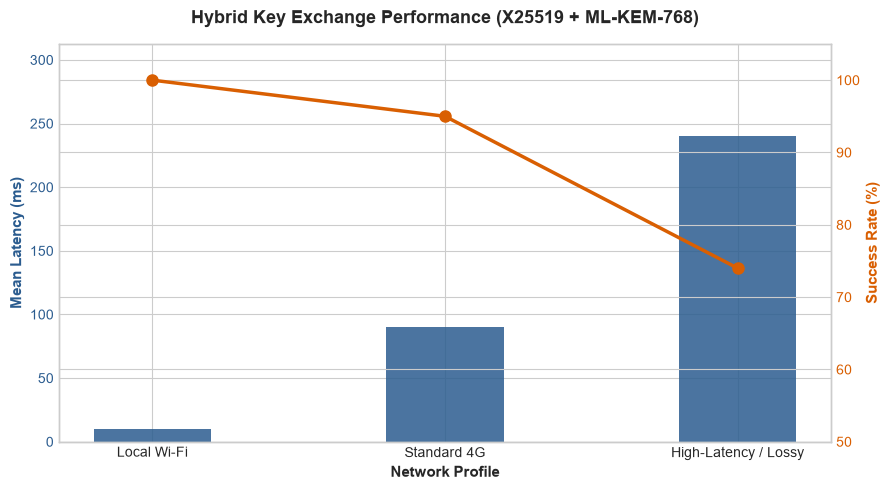

In [7]:
import matplotlib.pyplot as plt

# Set plotting style for academic paper aesthetic
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

fig, ax1 = plt.subplots(figsize=(9, 5))

# Bar chart for Mean Latency
profiles = df_results["Network Profile"]
mean_latencies = df_results["Mean Latency (ms)"]
success_rates = df_results["Success Rate (%)"]

color = '#2b5c8f'  # Professional academic blue
ax1.set_xlabel('Network Profile', fontweight='bold', fontsize=11)
ax1.set_ylabel('Mean Latency (ms)', color=color, fontweight='bold', fontsize=11)
bars = ax1.bar(profiles, mean_latencies, color=color, alpha=0.85, width=0.4, label='Mean Latency')
ax1.tick_params(axis='y', labelcolor=color)
ax1.set_ylim(0, max(mean_latencies) * 1.3)

# Second axis for Success Rate
ax2 = ax1.twinx()
color_line = '#d95f02'  # Contrast burnt orange
ax2.set_ylabel('Success Rate (%)', color=color_line, fontweight='bold', fontsize=11)
line = ax2.plot(profiles, success_rates, color=color_line, marker='o', linewidth=2.5, markersize=8, label='Success Rate')
ax2.tick_params(axis='y', labelcolor=color_line)
ax2.set_ylim(50, 105)

# Title and Layout
plt.title('Hybrid Key Exchange Performance (X25519 + ML-KEM-768)', fontsize=13, fontweight='bold', pad=15)
fig.tight_layout()

# Save figure directly for your LaTeX thesis document!
plt.savefig('hybrid_performance_evaluation.png', dpi=300, bbox_inches='tight')
plt.show()